In [30]:


import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split


print("PyTorch:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch: 2.14.0+rocm10.1.0
Device: cuda


In [31]:

colums = ["center", "left", "right", "steering", "throttle", "brake", "speed"]
files = pd.read_csv("data/driving_log.csv", header=None, names=colums)

data = files[["center", "left", "right"]]
y = files[["steering"]]
print(data.head())


                                              center  \
0  /home/peter/Desktop/self-driving-car/data/IMG/...   
1  /home/peter/Desktop/self-driving-car/data/IMG/...   
2  /home/peter/Desktop/self-driving-car/data/IMG/...   
3  /home/peter/Desktop/self-driving-car/data/IMG/...   
4  /home/peter/Desktop/self-driving-car/data/IMG/...   

                                                left  \
0  /home/peter/Desktop/self-driving-car/data/IMG/...   
1  /home/peter/Desktop/self-driving-car/data/IMG/...   
2  /home/peter/Desktop/self-driving-car/data/IMG/...   
3  /home/peter/Desktop/self-driving-car/data/IMG/...   
4  /home/peter/Desktop/self-driving-car/data/IMG/...   

                                               right  
0  /home/peter/Desktop/self-driving-car/data/IMG/...  
1  /home/peter/Desktop/self-driving-car/data/IMG/...  
2  /home/peter/Desktop/self-driving-car/data/IMG/...  
3  /home/peter/Desktop/self-driving-car/data/IMG/...  
4  /home/peter/Desktop/self-driving-car/data/IMG/..

In [32]:
image_dir = Path("data/IMG")

# Convert center, left, right columns into rows
data = files.melt(
    id_vars=["steering"],
    value_vars=["center", "left", "right"],
    var_name="camera",
    value_name="filename"
)

# Correct steering angles (negative = left)
correction = 0.2

data["steering"] += data["camera"].map({
    "center": 0,
    "left": -correction,
    "right": correction
})

# Load and crop images
images = []

for filename in data["filename"]:
    image_path = image_dir / Path(str(filename).strip()).name

    with Image.open(image_path) as image:
        cropped = image.crop((0, 55, image.width, image.height))
        images.append(np.array(cropped.convert("RGB")))

data["image"] = images


Straight: 58.64%
Left:     31.81%
Right:    9.55%


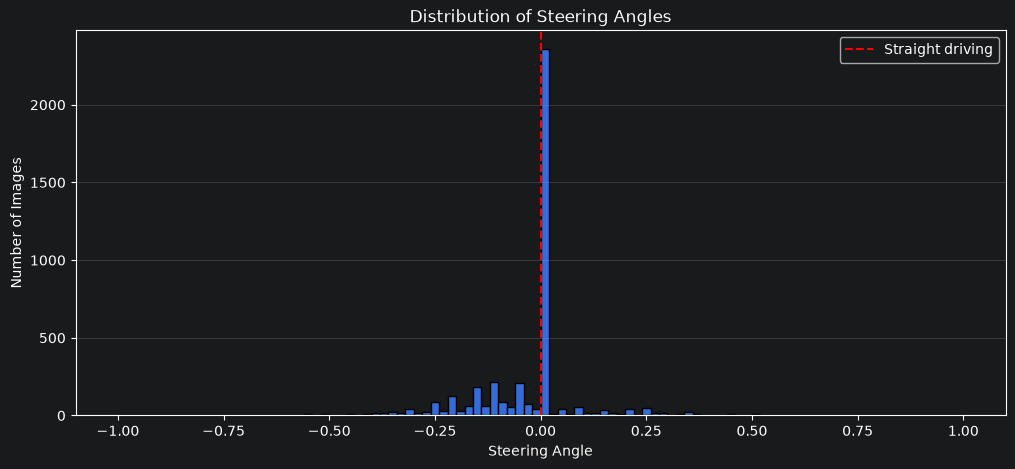

In [33]:
steering = pd.to_numeric(files["steering"], errors="coerce").dropna()

plt.figure(figsize=(12, 5))

plt.hist(steering, bins=100, edgecolor="black")

plt.xlabel("Steering Angle")
plt.ylabel("Number of Images")
plt.title("Distribution of Steering Angles")
plt.axvline(0, color="red", linestyle="--", label="Straight driving")
plt.legend()
plt.grid(axis="y", alpha=0.3)

straight = (steering.abs() < 0.05).sum()
left = (steering <= -0.05).sum()
right = (steering >= 0.05).sum()

total = len(steering)

print(f"Straight: {straight / total * 100:.2f}%")
print(f"Left:     {left / total * 100:.2f}%")
print(f"Right:    {right / total * 100:.2f}%")
plt.show()

data is wayyyy to centered for proper training. this fixes it by keeping only 30% of it

In [34]:
x = np.stack(data["image"].to_numpy())
y = data["steering"].to_numpy(dtype=np.float32)


X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

X_train = X_train.transpose(0, 3, 1, 2).astype(np.float32) / 255.0
X_test = X_test.transpose(0, 3, 1, 2).astype(np.float32) / 255.0

# Find completely straight driving (steering == 0)
straight_indices = np.where(y_train == 0)[0]
turning_indices = np.where(y_train != 0)[0]

# Randomly keep 70% of straight-driving examples
rng = np.random.default_rng(42)

straight_sample = rng.choice(
    straight_indices,
    size=int(len(straight_indices) * 0.70),
    replace=False
)

# Combine straight and turning examples
keep_indices = np.concatenate([
    straight_sample,
    turning_indices
])

# Shuffle
rng.shuffle(keep_indices)

# Apply the same indices to images AND steering angles
X_train = X_train[keep_indices]
y_train = y_train[keep_indices]


print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print(f"Straight driving: {(y_train == 0).mean() * 100:.2f}%")

Training images: 9685
Testing images: 2570
Straight driving: 14.21%


In [35]:
import torch.nn as nn

class DrivingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.relu = nn.ReLU()
        self.conv1 = nn.Conv2d(3, 24, 5, 2)
        self.conv2 = nn.Conv2d(24, 36, 5, 2)
        self.conv3 = nn.Conv2d(36, 48, 5, 2)
        self.conv4 = nn.Conv2d(48, 64, 3, 1)
        self.conv5 = nn.Conv2d(64, 64, 3, 1)
        self.fc1 = nn.Linear(12672, 100)
        self.fc2 = nn.Linear(100, 50)
        self.fc3 = nn.Linear(50, 10)
        self.fc4 = nn.Linear(10, 1)


    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.relu(self.conv4(x))
        x = self.relu(self.conv5(x))
        x = torch.flatten(x, start_dim=1)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.fc4(x)
        return x

In [36]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DrivingCNN().to(device)


X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)


from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)


In [ ]:

epochs = 100
patience = 10

best_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(epochs):

    # Training
    model.train()
    train_loss = 0

    for images, steering in train_loader:
        images = images.to(device)
        steering = steering.to(device).view(-1, 1)

        optimizer.zero_grad()

        predictions = model(images)

        loss = criterion(predictions, steering)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)

    # Evaluation
    model.eval()
    test_loss = 0

    with torch.no_grad():
        for images, steering in test_loader:
            images = images.to(device)
            steering = steering.to(device).view(-1, 1)

            predictions = model(images)
            loss = criterion(predictions, steering)

            test_loss += loss.item() * images.size(0)
            if test_loss < best_loss:
                best_loss = test_loss
                epochs_without_improvement = 0

    # Save the best model
                torch.save(model.state_dict(), "best_driving_model.pth")

            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= patience:
                print(f"Early stopping at epoch {epoch + 1}")
                break

    test_loss /= len(test_loader.dataset)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Test Loss: {test_loss:.5f}"
    )

Early stopping at epoch 1
Epoch 1/100 | Train Loss: 0.05430 | Test Loss: 0.00678
Early stopping at epoch 2
Epoch 2/100 | Train Loss: 0.05115 | Test Loss: 0.00653
Early stopping at epoch 3
Epoch 3/100 | Train Loss: 0.04893 | Test Loss: 0.00609
Early stopping at epoch 4
Epoch 4/100 | Train Loss: 0.02877 | Test Loss: 0.00345
Early stopping at epoch 5
Epoch 5/100 | Train Loss: 0.02181 | Test Loss: 0.00296
Early stopping at epoch 6
Epoch 6/100 | Train Loss: 0.02059 | Test Loss: 0.00299
Early stopping at epoch 7
Epoch 7/100 | Train Loss: 0.01989 | Test Loss: 0.00023
Early stopping at epoch 8
Epoch 8/100 | Train Loss: 0.01933 | Test Loss: 0.00273
Early stopping at epoch 9
Epoch 9/100 | Train Loss: 0.01875 | Test Loss: 0.00260
Early stopping at epoch 10
Epoch 10/100 | Train Loss: 0.01825 | Test Loss: 0.00245
Early stopping at epoch 11
Epoch 11/100 | Train Loss: 0.01749 | Test Loss: 0.00017
Early stopping at epoch 12
Epoch 12/100 | Train Loss: 0.01714 | Test Loss: 0.00241
Early stopping at epoc

In [ ]:
model.eval()

with torch.no_grad():
    predictions = model(
        X_test_tensor.to(device)
    ).cpu().numpy().flatten()

plt.figure(figsize=(12, 5))

plt.plot(y_test[:200], label="Actual Steering")
plt.plot(predictions[:200], label="Predicted Steering")

plt.xlabel("Sample")
plt.ylabel("Steering Angle")
plt.title("Actual vs Predicted Steering")
plt.legend()
plt.show()